In [1]:
import os, sys, subprocess
from pathlib import Path

# print("Python kernel:", sys.executable)

IS_COLAB = 'COLAB_RELEASE_TAG' in os.environ or 'google.colab' in sys.modules
USE_GOOGLE_DRIVE = True
RUN_NAME = 'simplified_v1'
N_PAIRS = 1000
REUSE_RESULTS = True  
TARGET_TRAIN_STEPS = None  

if IS_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'diffusers==0.35.1', 'transformers==4.49.0', 'accelerate==1.10.1',
        'peft==0.17.1', 'safetensors==0.6.2', 'huggingface-hub==0.34.4',
        'datasets==3.6.0', 'numpy', 'pandas', 'pillow', 'matplotlib'])
    NOTEBOOK_DIR = Path('/content/milestone2')
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        NOTEBOOK_DIR = Path('/content/drive/MyDrive/IE7615_Generative/Milestone2')
else:
    cwd = Path.cwd()
    NOTEBOOK_DIR = cwd if cwd.name == 'milestone 2' else cwd / 'submission/milestone 2'

In [2]:
import json, csv, time, random, hashlib, shutil, contextlib, textwrap, re, unicodedata, zipfile
from collections import defaultdict
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from datasets import load_dataset
from diffusers import StableDiffusionPipeline, DDPMScheduler, DDIMScheduler, DPMSolverMultistepScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig, get_peft_model_state_dict, set_peft_model_state_dict
from transformers import CLIPModel, CLIPProcessor

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
torch.set_num_threads(8)
MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
MODEL_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
SCORE_MODEL = 'openai/clip-vit-base-patch32'
SCORE_REVISION = '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'
SETTINGS = dict(
    train_steps=200 if DEVICE == 'cuda' else 40,
    train_resolution=512 if DEVICE == 'cuda' else 256,
    accumulation=1, val_count=4, save_every=50 if DEVICE == 'cuda' else 10,
    sample_resolution=512, sample_steps=20,
    sweep_resolution=512 if DEVICE == 'cuda' else 256,
    sweep_steps=20 if DEVICE == 'cuda' else 15, sweep_prompts=2,
)
ARTIFACTS = NOTEBOOK_DIR / 'artifacts'
RUN = ARTIFACTS / RUN_NAME
RUN.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path('/content/milestone2_data') if IS_COLAB else NOTEBOOK_DIR
PROCESSED = DATA_ROOT / 'artifacts/processed'

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines()]

def write_json(path, data):
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')

def write_jsonl(path, rows):
    path.write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in rows), encoding='utf-8')

def relative(path):
    return path.relative_to(NOTEBOOK_DIR).as_posix()

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == 'cuda':
        torch.cuda.manual_seed_all(seed)

def synchronize():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


config_path = RUN / 'config.json'
if config_path.exists():
    run_config = read_json(config_path)
    SETTINGS = run_config['settings'].copy()
    SEED, MODEL_ID, MODEL_REVISION = run_config['seed'], run_config['model'], run_config['revision']
    if (RUN / 'training/training.json').exists():
        SETTINGS['train_steps'] = read_json(RUN / 'training/training.json')['config']['steps']
    print('Loaded saved experiment settings:', config_path)
else:
    run_config = dict(settings=SETTINGS.copy(), seed=SEED, model=MODEL_ID,
        revision=MODEL_REVISION, device=DEVICE, dtype=str(DTYPE), torch_version=torch.__version__)
if TARGET_TRAIN_STEPS is not None:
    SETTINGS['train_steps'] = TARGET_TRAIN_STEPS
seed_all(SEED)
if not config_path.exists():
    run_config['settings'] = SETTINGS.copy()
    write_json(config_path, run_config)

display(pd.DataFrame([SETTINGS]))
print('Device:', DEVICE, '| Output:', RUN)

Loaded saved experiment settings: e:\sxx\northeastern university\courses\26fall\Deep Learning\project\generative project\submission\milestone 2\artifacts\simplified_v1\config.json


,train_steps,train_resolution,accumulation,val_count,save_every,sample_resolution,sample_steps,sweep_resolution,sweep_steps,sweep_prompts
0,200,512,1,4,50,512,20,512,20,2


Device: cpu | Output: e:\sxx\northeastern university\courses\26fall\Deep Learning\project\generative project\submission\milestone 2\artifacts\simplified_v1


In [3]:
DATASET_ID = 'lmms-lab-encoder/flickr30k'
DATASET_REVISION = '765d117f3eec816f2bfdc2d73ebb50a6f77b86a4'
RAW_CANDIDATES = 5500
IMAGE_SIZE = 512

def clean_caption(text):
    text = unicodedata.normalize('NFKC', text)
    text = ''.join(c if c.isprintable() else ' ' for c in text)
    return re.sub(r'\s+', ' ', text).strip()

def download_flickr30k(raw):
    (raw / 'images').mkdir(parents=True, exist_ok=True)
    stream = load_dataset(DATASET_ID, split='test', revision=DATASET_REVISION,
                          streaming=True).shuffle(seed=SEED, buffer_size=2048)
    with (raw / 'captions.csv').open('w', encoding='utf-8', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['image', 'caption'])
        writer.writeheader()
        for i, record in enumerate(stream.take(RAW_CANDIDATES)):
            name = f'{i:06d}.png'
            record['image'].convert('RGB').save(raw / 'images' / name)
            for caption in record['caption']:
                writer.writerow(dict(image=name, caption=caption))
            if (i + 1) % 100 == 0:
                print(f'Downloaded {i + 1}/{RAW_CANDIDATES}', flush=True)

def prepare_flickr30k(raw):
    (PROCESSED / 'images').mkdir(parents=True, exist_ok=True)
    grouped = defaultdict(list)
    with (raw / 'captions.csv').open(encoding='utf-8-sig', newline='') as f:
        for row in csv.DictReader(f):
            caption = clean_caption(row['caption'])
            if caption and caption.casefold() not in {'nan', 'none', 'null'} and caption not in grouped[row['image']]:
                grouped[row['image']].append(caption)
    rng = random.Random(SEED)
    names = sorted(grouped)
    rng.shuffle(names)
    selected, seen = [], set()
    for name in names:
        with Image.open(raw / 'images' / name) as original:
            rgb = ImageOps.exif_transpose(original).convert('RGB')
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            if digest in seen:
                continue
            image = ImageOps.fit(rgb, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.LANCZOS)
            image.save(PROCESSED / 'images' / f'{digest}.png')
            selected.append(dict(id=digest + '_0', image_id=digest, source_name=name,
                image=f'artifacts/processed/images/{digest}.png', original_size=list(rgb.size),
                caption=rng.choice(grouped[name])))
            seen.add(digest)
        if len(selected) == N_PAIRS:
            break
    assert len(selected) == N_PAIRS
    random.Random(SEED).shuffle(selected)
    n_eval = N_PAIRS // 10
    groups = dict(train=selected[2*n_eval:], val=selected[n_eval:2*n_eval], test=selected[:n_eval])
    for split, rows in groups.items():
        write_jsonl(PROCESSED / f'{split}.jsonl', [dict(row, split=split) for row in rows])

sibling = NOTEBOOK_DIR.parent / 'milestone 1/artifacts/processed'
cache = NOTEBOOK_DIR / f'flickr30k_{N_PAIRS}_seed{SEED}.zip'
if not (PROCESSED / 'train.jsonl').exists():
    if not IS_COLAB and sibling.exists():
        shutil.copytree(sibling, PROCESSED, dirs_exist_ok=True)
    elif IS_COLAB and cache.exists():
        # This ZIP is produced by this notebook from its own processed-data folder.
        shutil.unpack_archive(str(cache), str(PROCESSED.parent))
    else:
        raw = DATA_ROOT / 'raw/flickr30k'
        download_flickr30k(raw)
        prepare_flickr30k(raw)
if IS_COLAB and not cache.exists():
    shutil.make_archive(str(cache.with_suffix('')), 'zip', PROCESSED.parent, 'processed')

splits = {s: read_jsonl(PROCESSED / f'{s}.jsonl') for s in ['train', 'val', 'test']}
ids = {s: {r['image_id'] for r in rows} for s, rows in splits.items()}
assert not (ids['train'] & ids['val'] or ids['train'] & ids['test'] or ids['val'] & ids['test'])
assert [len(splits[s]) for s in splits] == [N_PAIRS - 2*(N_PAIRS//10), N_PAIRS//10, N_PAIRS//10]
# Retain one scientific provenance check against Milestone 1, without file-integrity auditing.
canonical = {s: hashlib.sha256(json.dumps(rows, sort_keys=True, separators=(',', ':'),
    ensure_ascii=False).encode()).hexdigest() for s, rows in splits.items()}
M1_EQUIVALENT = canonical == {
    'train': '7fa487a26792c39cfde40a14e9ea62ec9a894dc17350bb931e6f9eae62b196c1',
    'val': 'e2cd2d39bb9740592423305a5897b0a6e739c99c0459b9ed9c5d7c3180dcecd0',
    'test': '49d53dc4366f398540d3b8602fd194b550c0aee7064caadea20fd6cedf7d26a0',
}
dataset_card = dict(dataset=DATASET_ID, revision=DATASET_REVISION, pairs=N_PAIRS,
    seed=SEED, image_size=IMAGE_SIZE, splits={s: len(rows) for s, rows in splits.items()},
    milestone1_equivalent=M1_EQUIVALENT)
write_json(RUN / 'dataset_card.json', dataset_card)
display(pd.DataFrame([dict(split=s, pairs=len(rows)) for s, rows in splits.items()]))
print('Exact Milestone 1 subset:', M1_EQUIVALENT)

DEMO = [
    dict(id='p01', prompt='A brown dog jumps over a fallen log in a green park.', seed=42),
    dict(id='p02', prompt='Two people in red jackets walk along a snowy mountain trail.', seed=43),
    dict(id='p03', prompt='A cyclist in a yellow shirt rides past a brick building.', seed=44),
    dict(id='p04', prompt='A child in a blue coat holds a red umbrella on a rainy street.', seed=45),
    dict(id='p05', prompt='Three people play basketball on an outdoor court at sunset.', seed=46),
]
VAL_PROMPTS = [dict(id=f'v{i+1:02}', prompt=r['caption'], seed=1042+i,
    source_image_id=r['image_id']) for i, r in enumerate(splits['val'][:SETTINGS['sweep_prompts']])]
write_json(RUN / 'prompts.json', dict(demonstration=DEMO, tuning_validation=VAL_PROMPTS))

,split,pairs
0,train,800
1,val,100
2,test,100


Exact Milestone 1 subset: True


In [4]:
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, revision=MODEL_REVISION,
    torch_dtype=DTYPE, use_safetensors=True).to(DEVICE)
pipe.enable_vae_slicing()
pipe.set_progress_bar_config(disable=True)
tokenizer, text_encoder, unet, vae = pipe.tokenizer, pipe.text_encoder, pipe.unet, pipe.vae
vae.to(dtype=torch.float32)
for module in (text_encoder, unet, vae):
    module.requires_grad_(False)
    module.eval()
BASE_SCHEDULER_CONFIG = dict(pipe.scheduler.config)
noise_scheduler = DDPMScheduler.from_config(BASE_SCHEDULER_CONFIG)
write_json(RUN / 'pretrained_scheduler.json', BASE_SCHEDULER_CONFIG)

@torch.no_grad()
def encode_texts(texts):
    tokens = tokenizer(texts, padding='max_length', truncation=True,
                       max_length=tokenizer.model_max_length, return_tensors='pt')
    return text_encoder(tokens.input_ids.to(DEVICE))[0]

probe = encode_texts([DEMO[0]['prompt'], '', DEMO[1]['prompt']])
assert probe.shape == (3, 77, unet.config.cross_attention_dim)
torch.save(probe.cpu(), RUN / 'conditioning_examples.pt')
print('CLIP embeddings:', tuple(probe.shape), '| UNet cross-attention:', unet.config.cross_attention_dim)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

CLIP embeddings: (3, 77, 768) | UNet cross-attention: 768


In [5]:
def make_scheduler(kind='ddim', spacing='leading', karras=False):
    if kind == 'ddim':
        return DDIMScheduler.from_config(BASE_SCHEDULER_CONFIG, timestep_spacing=spacing)
    return DPMSolverMultistepScheduler.from_config(BASE_SCHEDULER_CONFIG,
        timestep_spacing=spacing, algorithm_type='dpmsolver++', solver_order=2, use_karras_sigmas=karras)

@torch.no_grad()
def generate_one(prompt, seed, resolution, steps, guidance, scheduler='ddim', spacing='leading', karras=False):
    sampler = make_scheduler(scheduler, spacing, karras)
    sampler.set_timesteps(steps, device=DEVICE)
    hidden = torch.cat([encode_texts(['']), encode_texts([prompt])])
    generator = torch.Generator('cpu').manual_seed(seed)
    z = torch.randn((1, 4, resolution // 8, resolution // 8), generator=generator, dtype=torch.float32)
    z = z.to(DEVICE, dtype=DTYPE) * sampler.init_noise_sigma
    unet.eval()
    synchronize()
    start = time.perf_counter()
    for t in sampler.timesteps:
        model_input = sampler.scale_model_input(torch.cat([z, z]), t)
        prediction = unet(model_input, t, encoder_hidden_states=hidden).sample
        unconditional, conditional = prediction.chunk(2)
        prediction = unconditional + guidance * (conditional - unconditional)
        extra = {'eta': 0.0} if scheduler == 'ddim' else {}
        z = sampler.step(prediction, t, z, **extra).prev_sample
    decoded = vae.decode(z.float() / vae.config.scaling_factor, return_dict=False)[0]
    decoded, flags = pipe.run_safety_checker(decoded, DEVICE, text_encoder.dtype)
    image = pipe.image_processor.postprocess(decoded, output_type='pil', do_denormalize=[not flags[0]])[0]
    synchronize()
    metadata = dict(seconds=time.perf_counter()-start, timesteps=sampler.timesteps.cpu().tolist(),
                    safety_flag=bool(flags[0]))
    return image, metadata

def generate_run(name, prompts, settings, adapter='pretrained'):
    folder = RUN / name
    folder.mkdir(parents=True, exist_ok=True)
    if REUSE_RESULTS and (folder / 'manifest.jsonl').exists():
        saved = read_json(folder / 'run.json')
        if saved['settings'] == settings and saved['adapter'] == adapter:
            # print('Reusing saved images:', name)
            return read_jsonl(folder / 'manifest.jsonl')
    records = []
    for prompt in prompts:
        image, metadata = generate_one(prompt['prompt'], prompt['seed'], **settings)
        path = folder / f'{prompt["id"]}.png'
        image.save(path)
        records.append(dict(**prompt, image=relative(path), **metadata))
        print(f'{name}: {prompt["id"]} ({metadata["seconds"]:.1f}s)', flush=True)
    write_jsonl(folder / 'manifest.jsonl', records)
    write_json(folder / 'run.json', dict(settings=settings, adapter=adapter,
        model_revision=MODEL_REVISION, images=len(records), seconds=sum(r['seconds'] for r in records)))
    return records

BASELINE_SETTINGS = dict(resolution=SETTINGS['sample_resolution'], steps=SETTINGS['sample_steps'],
                        guidance=7.5, scheduler='ddim', spacing='leading', karras=False)
baseline = generate_run('baseline', DEMO, BASELINE_SETTINGS)
display(pd.DataFrame(baseline)[['id', 'prompt', 'seed', 'seconds', 'safety_flag']])

,id,prompt,seed,seconds,safety_flag
0,p01,A brown dog jumps over a fallen log in a green...,42,5.762141,False
1,p02,Two people in red jackets walk along a snowy m...,43,3.117011,False
2,p03,A cyclist in a yellow shirt rides past a brick...,44,3.152938,False
3,p04,A child in a blue coat holds a red umbrella on...,45,3.141334,False
4,p05,Three people play basketball on an outdoor cou...,46,3.155432,False


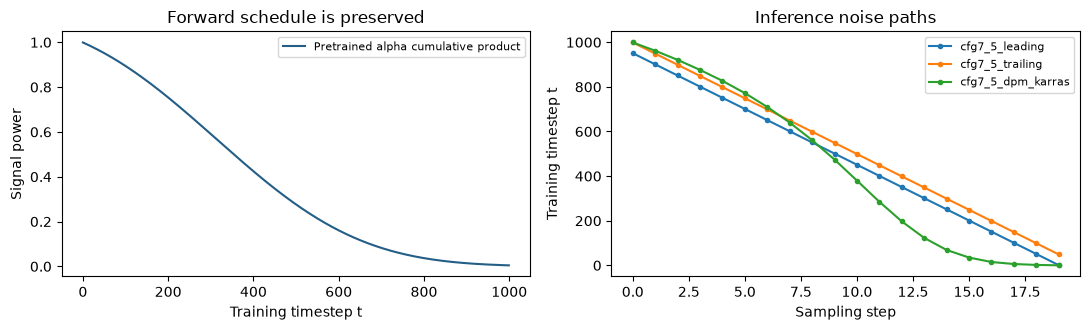

In [6]:
EXPERIMENTS = [
    dict(name='cfg7_5_leading', guidance=7.5, scheduler='ddim', spacing='leading', karras=False),
    dict(name='cfg3_leading', guidance=3.0, scheduler='ddim', spacing='leading', karras=False),
    dict(name='cfg12_leading', guidance=12.0, scheduler='ddim', spacing='leading', karras=False),
    dict(name='cfg7_5_trailing', guidance=7.5, scheduler='ddim', spacing='trailing', karras=False),
    dict(name='cfg7_5_dpm_karras', guidance=7.5, scheduler='dpm', spacing='leading', karras=True),
]
sweep_records = []
for experiment in EXPERIMENTS:
    settings = {k: v for k, v in experiment.items() if k != 'name'}
    settings.update(resolution=SETTINGS['sweep_resolution'], steps=SETTINGS['sweep_steps'])
    rows = generate_run('sweep/' + experiment['name'], VAL_PROMPTS, settings)
    sweep_records.extend(dict(experiment=experiment['name'], **row) for row in rows)
write_jsonl(RUN / 'sweep_manifest.jsonl', sweep_records)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
t = np.arange(noise_scheduler.config.num_train_timesteps)
alpha = noise_scheduler.alphas_cumprod.cpu().numpy()
axes[0].plot(t, alpha, color='#245e87', label='Pretrained alpha cumulative product')
axes[0].set(xlabel='Training timestep t', ylabel='Signal power', title='Forward schedule is preserved')
axes[0].legend(fontsize=8)
for experiment in [EXPERIMENTS[0], EXPERIMENTS[3], EXPERIMENTS[4]]:
    row = next(r for r in sweep_records if r['experiment'] == experiment['name'])
    axes[1].plot(range(len(row['timesteps'])), row['timesteps'], marker='.', label=experiment['name'])
axes[1].set(xlabel='Sampling step', ylabel='Training timestep t', title='Inference noise paths')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN / 'noise_schedules.png', dpi=160)
plt.show()

experiment,cfg12_leading,cfg3_leading,cfg7_5_dpm_karras,cfg7_5_leading,cfg7_5_trailing
prompt: change from DDIM leading / CFG 7.5,,,,,
v01,0.227,1.811,-2.276,0.0,-0.616
v02,0.155,-1.067,-0.870,0.0,0.810


,experiment,n,mean_clip,min_clip,max_clip,mean_seconds,flagged
0,cfg7_5_leading,2,32.408,30.154,34.663,3.199,0
1,cfg3_leading,2,32.780,31.965,33.595,3.246,0
2,cfg12_leading,2,32.599,30.381,34.818,3.306,0
3,cfg7_5_trailing,2,32.506,29.538,35.473,3.341,0
4,cfg7_5_dpm_karras,2,30.835,27.878,33.792,3.374,0


Provisional choice: cfg3_leading


,experiment,n,mean_clip,flagged
0,cfg7_5_leading,2,32.408,0
1,cfg3_leading,2,32.780,0


Provisional recommendation after the 512px check: cfg3_leading


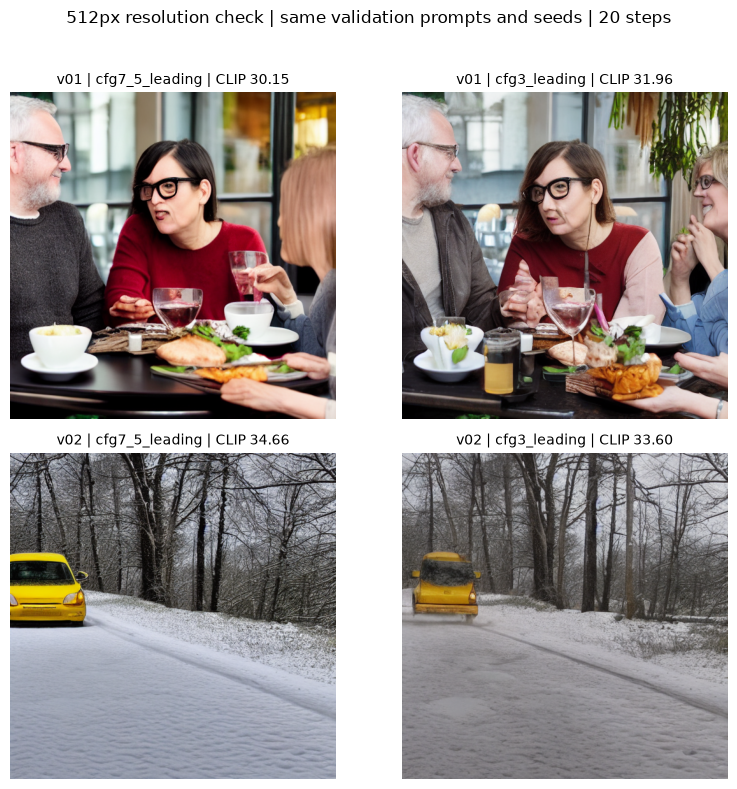

In [7]:
@torch.no_grad()
def score_images(records, cache_path):
    if REUSE_RESULTS and cache_path.exists():
        # print('Reusing saved CLIP scores:', cache_path.name)
        return pd.read_csv(cache_path)
    score_processor = CLIPProcessor.from_pretrained(SCORE_MODEL, revision=SCORE_REVISION)
    score_model = CLIPModel.from_pretrained(SCORE_MODEL, revision=SCORE_REVISION).to(DEVICE).eval()
    scores = []
    for row in records:
        with Image.open(NOTEBOOK_DIR / row['image']) as im:
            inputs = score_processor(text=[row['prompt']], images=[im.convert('RGB')],
                return_tensors='pt', padding=True, truncation=True).to(DEVICE)
        output = score_model(**inputs)
        cosine = (F.normalize(output.image_embeds, dim=-1) * F.normalize(output.text_embeds, dim=-1)).sum().item()
        scores.append(dict(experiment=row['experiment'], id=row['id'], seed=row['seed'],
            clip_score=100 * max(cosine, 0), seconds=row['seconds'], safety_flag=row['safety_flag']))
    return pd.DataFrame(scores)

scores_df = score_images(sweep_records, RUN / 'sweep_scores.csv')
scores_df.to_csv(RUN / 'sweep_scores.csv', index=False)
paired_scores = scores_df.pivot(index='id', columns='experiment', values='clip_score')
paired_deltas = paired_scores.subtract(paired_scores['cfg7_5_leading'], axis=0)
paired_deltas.to_csv(RUN / 'paired_clip_deltas.csv')
display(paired_deltas.round(3).rename_axis('prompt: change from DDIM leading / CFG 7.5'))
sweep_summary = scores_df.groupby('experiment', sort=False).agg(
    n=('id', 'size'), mean_clip=('clip_score', 'mean'), min_clip=('clip_score', 'min'),
    max_clip=('clip_score', 'max'), mean_seconds=('seconds', 'mean'), flagged=('safety_flag', 'sum')).reset_index()
sweep_summary.to_csv(RUN / 'sweep_summary.csv', index=False)
winner = str(sweep_summary.loc[sweep_summary['mean_clip'].idxmax(), 'experiment'])
selection = dict(name=winner, criterion='Highest mean CLIP ViT-B/32 on fixed validation pilot captions',
                  n=SETTINGS['sweep_prompts'], resolution=SETTINGS['sweep_resolution'],
                  score_model=SCORE_MODEL, score_revision=SCORE_REVISION,
                  scope='Provisional pilot selection; not validated at 512px or across seeds.')
write_json(RUN / 'selection.json', selection)
display(sweep_summary.round(3))
print('Provisional choice:', winner)

# Check whether the low-resolution ranking transfers to the native display resolution.
confirmation_records = []
confirmation_names = list(dict.fromkeys(['cfg7_5_leading', winner]))
for name in confirmation_names:
    experiment = next(e for e in EXPERIMENTS if e['name'] == name)
    settings = {k: v for k, v in experiment.items() if k != 'name'}
    settings.update(resolution=512, steps=SETTINGS['sweep_steps'])
    records = generate_run('confirmation_512/' + name, VAL_PROMPTS, settings)
    confirmation_records.extend(dict(experiment=name, **row) for row in records)
confirmation_df = score_images(confirmation_records, RUN / 'confirmation_scores_512.csv')
confirmation_df.to_csv(RUN / 'confirmation_scores_512.csv', index=False)
confirmation_summary = confirmation_df.groupby('experiment', sort=False).agg(
    n=('id', 'size'), mean_clip=('clip_score', 'mean'), flagged=('safety_flag', 'sum')).reset_index()
confirmation_summary.to_csv(RUN / 'confirmation_summary_512.csv', index=False)
recommended_name = str(confirmation_summary.loc[confirmation_summary.mean_clip.idxmax(), 'experiment'])
confirmation_means = dict(zip(confirmation_summary.experiment, confirmation_summary.mean_clip))
selection.update(confirmation_resolution=512, confirmation_steps=SETTINGS['sweep_steps'],
    confirmation_mean_clip=confirmation_means, recommended_name=recommended_name,
    scope='Provisional after a 512px check on the same validation captions; no independent cases or extra seeds.')
write_json(RUN / 'selection.json', selection)
display(confirmation_summary.round(3))
print('Provisional recommendation after the 512px check:', recommended_name)
fig, axes = plt.subplots(len(VAL_PROMPTS), len(confirmation_names), figsize=(4 * len(confirmation_names), 4 * len(VAL_PROMPTS)), squeeze=False)
for i, prompt in enumerate(VAL_PROMPTS):
    for j, name in enumerate(confirmation_names):
        row = next(r for r in confirmation_records if r['id'] == prompt['id'] and r['experiment'] == name)
        value = float(confirmation_df[(confirmation_df.id == prompt['id']) & (confirmation_df.experiment == name)].clip_score.iloc[0])
        with Image.open(NOTEBOOK_DIR / row['image']) as im:
            axes[i, j].imshow(im)
        axes[i, j].axis('off')
        axes[i, j].set_title(f'{prompt["id"]} | {name} | CLIP {value:.2f}', fontsize=10)
fig.suptitle(f'512px resolution check | same validation prompts and seeds | {SETTINGS["sweep_steps"]} steps')
fig.tight_layout(rect=[0, 0, 1, .96])
fig.savefig(NOTEBOOK_DIR / 'guidance_schedule_confirmation_512.png', dpi=150)
plt.show()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

In [8]:
TRAINING = dict(steps=SETTINGS['train_steps'], resolution=SETTINGS['train_resolution'],
                 accumulation=SETTINGS['accumulation'], rank=4, learning_rate=1e-4,
                 caption_dropout=0.1, gradient_clip=1.0, weight_decay=0.01,
                 save_every=SETTINGS['save_every'], val_count=SETTINGS['val_count'], seed=SEED)
TRAIN = RUN / 'training'
TRAIN.mkdir(exist_ok=True)
if (TRAIN / 'training.json').exists():
    TRAINING = read_json(TRAIN / 'training.json')['config'].copy()
    TRAINING['steps'] = SETTINGS['train_steps']
seed_all(SEED + 500)
if 'default' not in getattr(unet, 'peft_config', {}):
    unet.add_adapter(LoraConfig(r=TRAINING['rank'], lora_alpha=TRAINING['rank'],
                               init_lora_weights='gaussian', target_modules=['to_q', 'to_k', 'to_v', 'to_out.0']))
trainable = [p for p in unet.parameters() if p.requires_grad]
for p in trainable:
    p.data = p.data.float()
unet.enable_gradient_checkpointing()
optimizer = torch.optim.AdamW(trainable, lr=TRAINING['learning_rate'], weight_decay=TRAINING['weight_decay'])
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
trainable_count = sum(p.numel() for p in trainable)

def image_tensor(row):
    with Image.open(DATA_ROOT / row['image']) as im:
        im = ImageOps.fit(im.convert('RGB'), (TRAINING['resolution'], TRAINING['resolution']),
                          method=Image.Resampling.LANCZOS)
        array = np.asarray(im, dtype=np.float32).copy() / 127.5 - 1
    return torch.from_numpy(array).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

state_path = TRAIN / 'last_state.pt'
checkpoint = torch.load(state_path, map_location='cpu', weights_only=True) if state_path.exists() else None
TRAINING_UPDATED = checkpoint is None or checkpoint['step'] < TRAINING['steps']
if not TRAINING_UPDATED:
    
    set_peft_model_state_dict(unet, checkpoint['adapter'])
    training_info = read_json(TRAIN / 'training.json')
    TRAINING = training_info['config'].copy()
    SETTINGS['train_steps'] = checkpoint['step']
    best_step, best_loss = checkpoint['best_step'], checkpoint['best_loss']
    train_df = pd.read_csv(TRAIN / 'training_log.csv')
    # print(f'Loaded completed training: {checkpoint["step"]} updates; no optimizer updates required.')
    display(train_df[['step', 'train_loss', 'val_loss', 'seconds']].tail(6))
else:
    fixed_validation = []
    with torch.no_grad():
        generator = torch.Generator(device='cpu').manual_seed(SEED + 10000)
        for row in splits['val'][:TRAINING['val_count']]:
            latent = (vae.encode(image_tensor(row)).latent_dist.mode() * vae.config.scaling_factor).to(DTYPE)
            noise = torch.randn(latent.shape, generator=generator).to(DEVICE, dtype=DTYPE)
            times = torch.randint(0, noise_scheduler.config.num_train_timesteps, (1,), generator=generator).to(DEVICE)
            fixed_validation.append((noise_scheduler.add_noise(latent, noise, times), times,
                                     encode_texts([row['caption']]), noise))
    write_json(TRAIN / 'validation_cases.json', [dict(image_id=r['image_id'], timestep=int(case[1].item()))
        for r, case in zip(splits['val'], fixed_validation)])

    def amp_context():
        return torch.autocast('cuda', dtype=torch.float16) if DEVICE == 'cuda' else contextlib.nullcontext()

    @torch.no_grad()
    def validation_loss():
        unet.eval()
        values = []
        for noisy, times, hidden, target in fixed_validation:
            with amp_context():
                prediction = unet(noisy, times, encoder_hidden_states=hidden).sample
            values.append(float(F.mse_loss(prediction.float(), target.float()).cpu()))
        unet.train()
        return float(np.mean(values))

    def save_adapter(folder):
        folder.mkdir(parents=True, exist_ok=True)
        state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
        StableDiffusionPipeline.save_lora_weights(folder, unet_lora_layers=state, safe_serialization=True)

    log_path = TRAIN / 'training_log.csv'
    fields = ['step', 'train_loss', 'val_loss', 'lr', 'seconds', 'effective_batch', 'grad_norm',
              'caption_dropped', 'train_image_ids', 'timesteps']
    log_rows = []
    start_step, best_loss, best_step, pretrain_val = 0, float('inf'), None, None
    state_path = TRAIN / 'last_state.pt'
    if state_path.exists():
        state = checkpoint
        set_peft_model_state_dict(unet, state['adapter'])
        optimizer.load_state_dict(state['optimizer'])
        if state['scaler']:
            scaler.load_state_dict(state['scaler'])
        start_step, best_loss, best_step, pretrain_val = state['step'], state['best_loss'], state['best_step'], state['pretrain_val']
        if log_path.exists():
            with log_path.open(newline='', encoding='utf-8') as f:
                log_rows = [r for r in csv.DictReader(f) if int(r['step']) <= start_step]
        print('Restored optimizer step', start_step)
    else:
        pretrain_val = validation_loss()
        log_rows = [dict(step=0, train_loss='', val_loss=pretrain_val, lr=TRAINING['learning_rate'],
                         seconds=0, effective_batch=TRAINING['accumulation'], grad_norm='',
                         caption_dropped=0, train_image_ids='', timesteps='')]
        print(f'Before training: fixed validation MSE={pretrain_val:.6f}', flush=True)
    training_info = dict(status='running', kind='lora_training', config=TRAINING,
        trainable_parameters=trainable_count, frozen=['CLIP', 'VAE', 'base UNet'],
        training_pairs=len(splits['train']), validation_cases=TRAINING['val_count'],
        prediction_type=noise_scheduler.config.prediction_type, initial_val_loss=pretrain_val,
        scope='Early optimization only; validation is a fixed-case diagnostic, not a full validation estimate.')
    write_json(TRAIN / 'training.json', training_info)

    with log_path.open('w', newline='', encoding='utf-8') as log_file:
        writer = csv.DictWriter(log_file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(log_rows)
        log_file.flush()
        for step in range(start_step + 1, TRAINING['steps'] + 1):
            seed_all(SEED + 20000 + step)
            synchronize()
            began = time.perf_counter()
            unet.train()
            optimizer.zero_grad(set_to_none=True)
            rng = np.random.default_rng(SEED + step)
            indices = rng.choice(len(splits['train']), size=TRAINING['accumulation'], replace=False)
            losses, used_ids, used_times, dropped = [], [], [], 0
            for idx in indices:
                row = splits['train'][int(idx)]
                drop = random.random() < TRAINING['caption_dropout']
                dropped += int(drop)
                with torch.no_grad():
                    latent = (vae.encode(image_tensor(row)).latent_dist.sample() * vae.config.scaling_factor).to(DTYPE)
                    hidden = encode_texts(['' if drop else row['caption']])
                    noise = torch.randn_like(latent)
                    times = torch.randint(0, noise_scheduler.config.num_train_timesteps, (1,), device=DEVICE)
                    noisy = noise_scheduler.add_noise(latent, noise, times)
                    target = noise
                with amp_context():
                    prediction = unet(noisy, times, encoder_hidden_states=hidden).sample
                    loss = F.mse_loss(prediction.float(), target.float())
                scaler.scale(loss / TRAINING['accumulation']).backward()
                losses.append(float(loss.detach().cpu()))
                used_ids.append(row['image_id'])
                used_times.append(int(times.item()))
            scaler.unscale_(optimizer)
            grad_norm = float(torch.nn.utils.clip_grad_norm_(trainable, TRAINING['gradient_clip']))
            scaler.step(optimizer)
            scaler.update()
            val = ''
            checkpoint_step = step % TRAINING['save_every'] == 0 or step == TRAINING['steps']
            if checkpoint_step:
                val = validation_loss()
                save_adapter(TRAIN / f'step-{step}')
                if val < best_loss:
                    best_loss, best_step = val, step
                    save_adapter(TRAIN / 'best')
                    torch.save(get_peft_model_state_dict(unet), TRAIN / 'best_adapter.pt')
                    write_json(TRAIN / 'best' / 'selection.json', dict(step=best_step, val_loss=best_loss))
            synchronize()
            log_row = dict(step=step, train_loss=float(np.mean(losses)), val_loss=val,
                lr=optimizer.param_groups[0]['lr'], seconds=time.perf_counter()-began,
                effective_batch=TRAINING['accumulation'], grad_norm=grad_norm, caption_dropped=dropped,
                train_image_ids='|'.join(used_ids), timesteps='|'.join(map(str, used_times)))
            writer.writerow(log_row)
            log_file.flush()
            if checkpoint_step:
                state = dict(step=step, best_loss=best_loss, best_step=best_step,
                             pretrain_val=pretrain_val, adapter=get_peft_model_state_dict(unet),
                             optimizer=optimizer.state_dict(), scaler=scaler.state_dict())
                temp = TRAIN / 'last_state.pt.partial'
                torch.save(state, temp)
                temp.replace(state_path)
            print(f'step {step:03d}/{TRAINING["steps"]}: loss={log_row["train_loss"]:.6f} val={val} ({log_row["seconds"]:.1f}s)', flush=True)

    training_info.update(status='complete', optimizer_steps=TRAINING['steps'], best_step=best_step,
                         best_val_loss=best_loss, final_checkpoint_step=TRAINING['steps'])
    write_json(TRAIN / 'training.json', training_info)
    train_df = pd.read_csv(log_path)
    display(train_df[['step', 'train_loss', 'val_loss', 'seconds']].tail(6))
    print('Best adapter:', best_step, 'validation MSE:', best_loss)

,step,train_loss,val_loss,seconds
195,195,0.015363,NaN,0.697065
196,196,0.125125,NaN,0.682900
197,197,0.358785,NaN,0.712947
198,198,0.384021,NaN,0.691681
199,199,0.080411,NaN,0.693848
200,200,0.435603,0.177047,1.430278


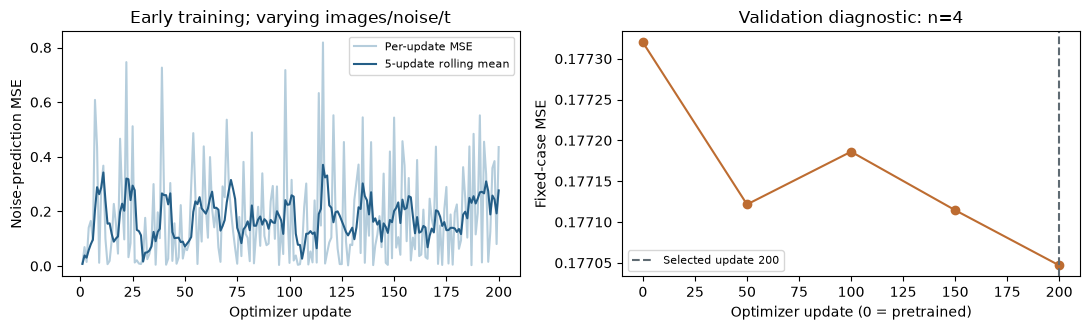

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
updates = train_df[train_df.step > 0]
axes[0].plot(updates.step, updates.train_loss, alpha=.35, color='#2b719b', label='Per-update MSE')
axes[0].plot(updates.step, updates.train_loss.rolling(5, min_periods=1).mean(), color='#245e87', label='5-update rolling mean')
axes[0].set(xlabel='Optimizer update', ylabel='Noise-prediction MSE', title='Early training; varying images/noise/t')
axes[0].legend(fontsize=8)
validation_df = train_df.dropna(subset=['val_loss'])
axes[1].plot(validation_df.step, validation_df.val_loss, '-o', color='#bd6c31')
axes[1].axvline(best_step, color='#5f6b73', linestyle='--', label=f'Selected update {best_step}')
axes[1].set(xlabel='Optimizer update (0 = pretrained)', ylabel='Fixed-case MSE', title=f'Validation diagnostic: n={TRAINING["val_count"]}')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN / 'training_loss.png', dpi=160)
plt.show()

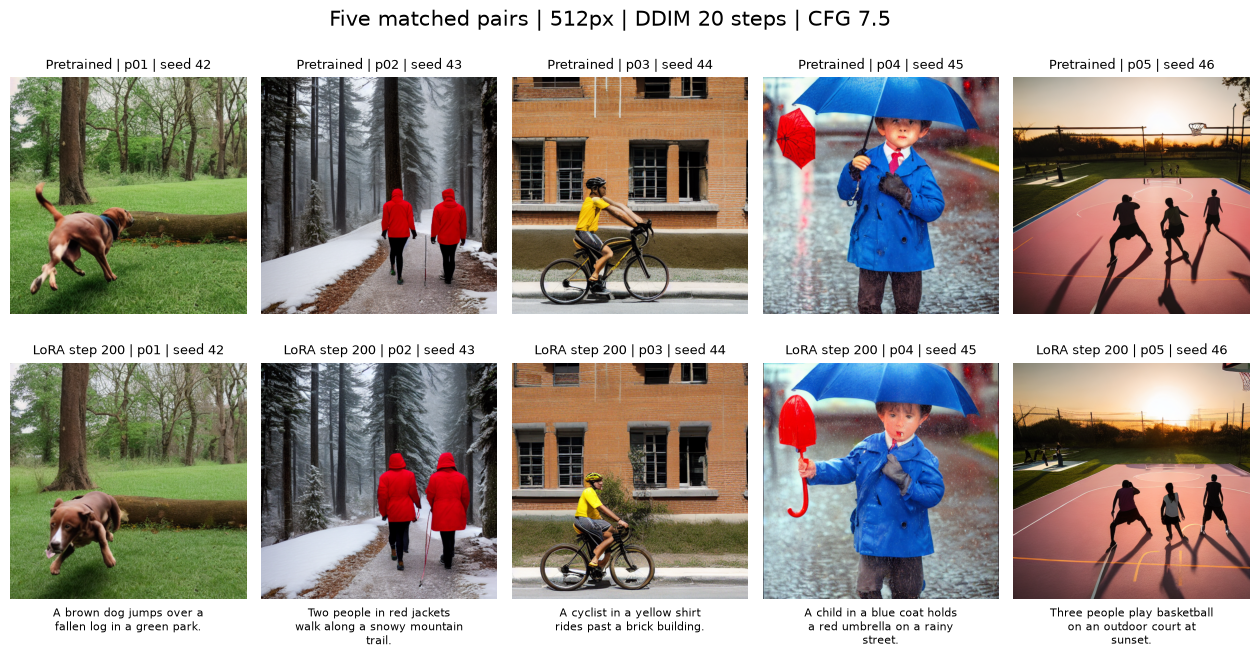

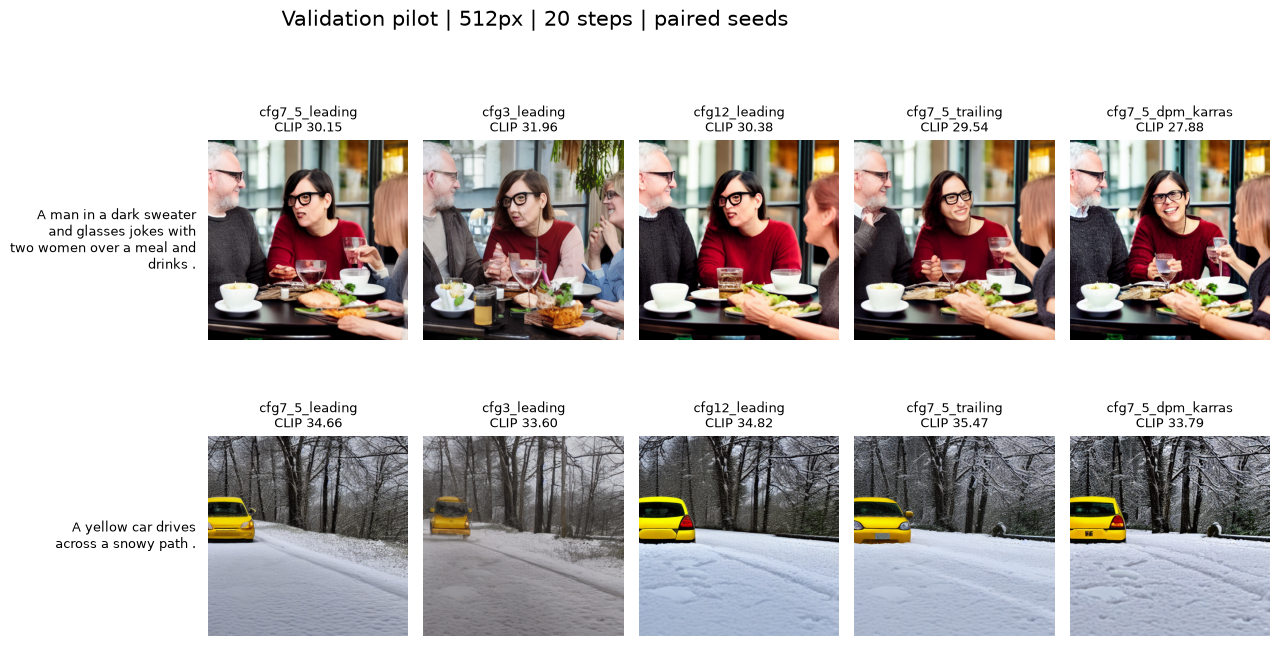

In [10]:
selected_state = torch.load(TRAIN / 'best_adapter.pt', map_location='cpu', weights_only=True)
set_peft_model_state_dict(unet, selected_state)
unet.eval()
unet.disable_gradient_checkpointing()
early = generate_run('early_lora', DEMO, BASELINE_SETTINGS, adapter=dict(step=best_step))

# Convenient submission copies: ten images and an explicit prompt/seed/model manifest.
SAMPLES = NOTEBOOK_DIR / 'early_samples'
SAMPLES.mkdir(exist_ok=True)
sample_rows = []
for group, rows in [('baseline', baseline), ('early_lora', early)]:
    for row in rows:
        target = SAMPLES / f'{group}_{row["id"]}.png'
        shutil.copy2(NOTEBOOK_DIR / row['image'], target)
        sample_rows.append(dict(group=group, **{k: v for k, v in row.items() if k != 'image'},
            image=relative(target), settings=BASELINE_SETTINGS,
            adapter_step=best_step if group == 'early_lora' else None))
write_jsonl(SAMPLES / 'manifest.jsonl', sample_rows)

fig, axes = plt.subplots(2, 5, figsize=(16, 7.3))
for row_index, (label, records) in enumerate([('Pretrained', baseline), (f'LoRA step {best_step}', early)]):
    for j, row in enumerate(records):
        with Image.open(NOTEBOOK_DIR / row['image']) as im:
            axes[row_index, j].imshow(im)
        axes[row_index, j].axis('off')
        axes[row_index, j].set_title(f'{label} | {row["id"]} | seed {row["seed"]}', fontsize=9)
        if row_index == 1:
            axes[row_index, j].text(.5, -.03, textwrap.fill(row['prompt'], 29),
                                   transform=axes[row_index, j].transAxes, ha='center', va='top', fontsize=8)
fig.suptitle(f'Five matched pairs | {SETTINGS["sample_resolution"]}px | DDIM {SETTINGS["sample_steps"]} steps | CFG 7.5', fontsize=15)
fig.subplots_adjust(top=.9, bottom=.16, hspace=.12, wspace=.06)
fig.savefig(NOTEBOOK_DIR / 'early_samples_contact_sheet.png', dpi=170, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(len(VAL_PROMPTS), len(EXPERIMENTS), figsize=(15, 3.5 * len(VAL_PROMPTS)), squeeze=False)
for i, prompt in enumerate(VAL_PROMPTS):
    for j, experiment in enumerate(EXPERIMENTS):
        row = next(r for r in sweep_records if r['id'] == prompt['id'] and r['experiment'] == experiment['name'])
        score = float(scores_df[(scores_df.id == prompt['id']) & (scores_df.experiment == experiment['name'])].clip_score.iloc[0])
        with Image.open(NOTEBOOK_DIR / row['image']) as im:
            axes[i, j].imshow(im)
        axes[i, j].axis('off')
        axes[i, j].set_title(f'{experiment["name"]}\nCLIP {score:.2f}', fontsize=9)
        if j == 0:
            axes[i, j].text(-.06, .5, textwrap.fill(prompt['prompt'], 25), transform=axes[i, j].transAxes,
                            ha='right', va='center', fontsize=9)
fig.suptitle(f'Validation pilot | {SETTINGS["sweep_resolution"]}px | {SETTINGS["sweep_steps"]} steps | paired seeds', fontsize=15)
fig.tight_layout(rect=[.14, 0, 1, .95])
fig.savefig(NOTEBOOK_DIR / 'guidance_schedule_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

In [12]:
summary = dict(run_name=RUN_NAME, completed_utc=datetime.now(timezone.utc).isoformat(),
    device=DEVICE, settings=SETTINGS, dataset=dataset_card,
    baseline_count=len(baseline), early_lora_count=len(early), sweep_count=len(sweep_records),
    confirmation_count=len(confirmation_records), training=training_info, selection=selection,
    unique_training_images=len(unique_training_ids), safety_flag_count=flagged,
    observations='observations.md', visual_review='Edit notes after inspecting the generated images.')
if REUSE_RESULTS and not TRAINING_UPDATED and (RUN / 'execution_summary.json').exists():
    summary = read_json(RUN / 'execution_summary.json')
else:
    write_json(RUN / 'execution_summary.json', summary)
display(pd.DataFrame([dict(samples=len(sample_rows), pilot_images=len(sweep_records),
    optimizer_steps=TRAINING['steps'], best_step=best_step, best_val_mse=best_loss)]))

,samples,pilot_images,optimizer_steps,best_step,best_val_mse
0,10,10,200,200,0.177047
